In [1]:
%run 00_functions.ipynb

## 1. Data Splitting

In [2]:
# Load the feature-engineered dataset
df = pd.read_csv("../data/processed/bitcoin_feature_engineered.csv")

# Display the dataset information
print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())

df.head()

Dataset shape: (3184, 9)
Date range: 2018-01-20 to 2026-10-08


,date,open,high,low,close,volume,MACD,RSI,SMA
0,2018-01-20,11579.240234,13082.238281,11567.291016,12858.858398,143900,-569.638525,66.179585,14051.718457
1,2018-01-21,12857.081055,12860.202148,11164.538086,11594.896484,206959,-630.799598,59.335267,13959.219287
2,2018-01-22,11597.452148,11970.898438,10136.767578,10864.833984,201726,-729.767823,55.748913,13764.754492
3,2018-01-23,10869.032227,11437.955078,10056.577148,10903.190430,188365,-795.930814,55.899728,13552.083008
4,2018-01-24,10899.393555,11549.520508,10584.529297,11452.302734,136064,-794.893648,58.101280,13365.694141


In [3]:
# Convert date to datetime format
df["date"] = pd.to_datetime(df["date"])

# Split development and test data chronologically
development_df = df[
    (df["date"] >= "2018-01-01") &
    (df["date"] < "2025-01-01")
].copy()

test_df = df[
    (df["date"] >= "2025-01-01") &
    (df["date"] < "2027-01-01")
].copy()

# Check the split results
print("Development data:")
print("Shape:", development_df.shape)
print("Date range:", development_df["date"].min(), "to", development_df["date"].max())

print("\nTest data:")
print("Shape:", test_df.shape)
print("Date range:", test_df["date"].min(), "to", test_df["date"].max())

Development data:
Shape: (2538, 9)
Date range: 2018-01-20 00:00:00 to 2024-12-31 00:00:00

Test data:
Shape: (646, 9)
Date range: 2025-01-01 00:00:00 to 2026-10-08 00:00:00


In [4]:
# Split development data chronologically into training and validation
split_index = int(len(development_df) * 0.8)

train_df = development_df.iloc[:split_index].copy()
validation_df = development_df.iloc[split_index:].copy()

# Check the split results
print("Training data:")
print("Shape:", train_df.shape)
print("Date range:", train_df["date"].min(), "to", train_df["date"].max())

print("\nValidation data:")
print("Shape:", validation_df.shape)
print("Date range:", validation_df["date"].min(), "to", validation_df["date"].max())

Training data:
Shape: (2030, 9)
Date range: 2018-01-20 00:00:00 to 2023-08-11 00:00:00

Validation data:
Shape: (508, 9)
Date range: 2023-08-12 00:00:00 to 2024-12-31 00:00:00


In [5]:
# Define the input features
feature_columns = [
    "open",
    "high",
    "low",
    "close",
    "volume",
    "RSI",
    "SMA",
    "MACD"
]

# Define the target variable
target_column = "close"

print("Input features:", feature_columns)
print("Target variable:", target_column)

Input features: ['open', 'high', 'low', 'close', 'volume', 'RSI', 'SMA', 'MACD']
Target variable: close


In [6]:
# Create the scaler
feature_scaler = MinMaxScaler(feature_range=(0, 1))

# Fit the scaler using training data only
feature_scaler.fit(train_df[feature_columns])

print("Min-Max Scaler fitted on training data.")

Min-Max Scaler fitted on training data.


In [7]:
# Apply the fitted scaler to all three datasets
X_train_scaled = feature_scaler.transform(train_df[feature_columns])
X_val_scaled = feature_scaler.transform(validation_df[feature_columns])
X_test_scaled = feature_scaler.transform(test_df[feature_columns])

print("Training data shape:", X_train_scaled.shape)
print("Validation data shape:", X_val_scaled.shape)
print("Test data shape:", X_test_scaled.shape)

Training data shape: (2030, 8)
Validation data shape: (508, 8)
Test data shape: (646, 8)


In [8]:
# Create a scaler for the target variable
target_scaler = MinMaxScaler(feature_range=(0, 1))

# Fit the scaler using training closing prices only
target_scaler.fit(train_df[["close"]])

print("Target scaler fitted on training closing prices.")

Target scaler fitted on training closing prices.


In [9]:
# Apply the fitted scaler to closing prices
y_train_scaled = target_scaler.transform(train_df[["close"]])
y_val_scaled = target_scaler.transform(validation_df[["close"]])
y_test_scaled = target_scaler.transform(test_df[["close"]])

print("Training target shape:", y_train_scaled.shape)
print("Validation target shape:", y_val_scaled.shape)
print("Test target shape:", y_test_scaled.shape)

Training target shape: (2030, 1)
Validation target shape: (508, 1)
Test target shape: (646, 1)


## 3. Look-back Window

In [10]:
# Define the look-back window
look_back = 90

print("Look-back window:", look_back, "days")

Look-back window: 90 days


In [11]:
def create_sequences(X, y, look_back):
    X_sequences = []
    y_targets = []

    for i in range(look_back, len(X)):
        X_sequences.append(X[i - look_back:i])
        y_targets.append(y[i])

    return np.array(X_sequences), np.array(y_targets)

In [12]:
# Create sequences for each dataset
X_train_seq, y_train_seq = create_sequences(
    X_train_scaled, y_train_scaled, look_back
)

X_val_seq, y_val_seq = create_sequences(
    X_val_scaled, y_val_scaled, look_back
)

X_test_seq, y_test_seq = create_sequences(
    X_test_scaled, y_test_scaled, look_back
)

# Check the sequence shapes
print("Training sequences:", X_train_seq.shape, y_train_seq.shape)
print("Validation sequences:", X_val_seq.shape, y_val_seq.shape)
print("Test sequences:", X_test_seq.shape, y_test_seq.shape)

Training sequences: (1940, 90, 8) (1940, 1)
Validation sequences: (418, 90, 8) (418, 1)
Test sequences: (556, 90, 8) (556, 1)


In [13]:
# Check missing values in the sequences
print("Missing values in X_train_seq:", np.isnan(X_train_seq).sum())
print("Missing values in y_train_seq:", np.isnan(y_train_seq).sum())

print("Missing values in X_val_seq:", np.isnan(X_val_seq).sum())
print("Missing values in y_val_seq:", np.isnan(y_val_seq).sum())

print("Missing values in X_test_seq:", np.isnan(X_test_seq).sum())
print("Missing values in y_test_seq:", np.isnan(y_test_seq).sum())

Missing values in X_train_seq: 0
Missing values in y_train_seq: 0
Missing values in X_val_seq: 0
Missing values in y_val_seq: 0
Missing values in X_test_seq: 0
Missing values in y_test_seq: 0


In [14]:
# Build the LSTM model
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(look_back, 8)),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(1)
])

# Display the model architecture
model.summary()

c:\Users\nyy32\OneDrive\Documents\UM_Master of Artifcial Inteligence\Thesis\Github\Cryptocurrency Forecasting\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 90, 64)         │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 90, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,137 (121.63 KB)

 Trainable params: 31,137 (121.63 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# Compile the LSTM model
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

print("LSTM model compiled successfully.")

LSTM model compiled successfully.


In [16]:
# Stop training if validation loss does not improve
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the LSTM model
history = model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    shuffle=False
)

Epoch 1/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0154 - mae: 0.0856 - val_loss: 0.1409 - val_mae: 0.3427
Epoch 2/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0086 - mae: 0.0696 - val_loss: 0.1488 - val_mae: 0.3545
Epoch 3/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0086 - mae: 0.0675 - val_loss: 0.1799 - val_mae: 0.3897
Epoch 4/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0098 - mae: 0.0729 - val_loss: 0.1725 - val_mae: 0.3821
Epoch 5/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0097 - mae: 0.0720 - val_loss: 0.1769 - val_mae: 0.3864
Epoch 6/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0104 - mae: 0.0702 - val_loss: 0.1577 - val_mae: 0.3660
Epoch 7/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0087 - mae: 0.0603 - val_loss: 0.1520 - val_mae: 0.3565
Epoch 8/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0086 - mae: 0.0595 - val_loss: 0.1377 - val_mae: 0.3400
Epoch 9/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.008

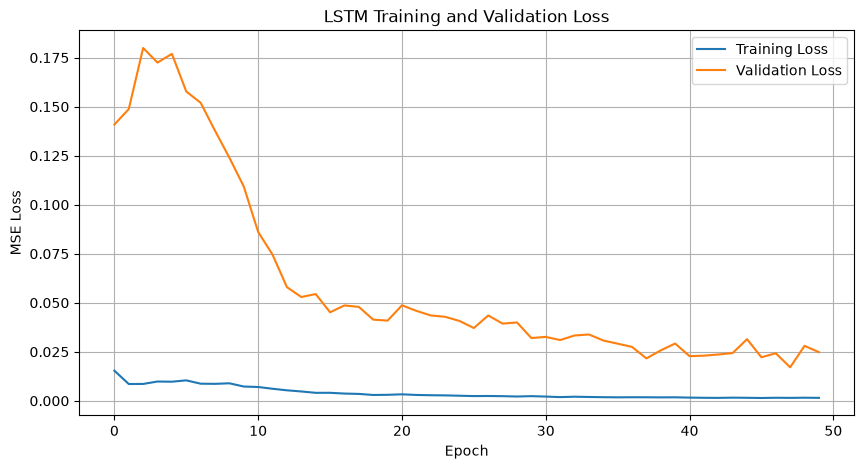

In [17]:
# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
# Predict the scaled closing prices
y_test_pred_scaled = model.predict(X_test_seq)

print("Prediction shape:", y_test_pred_scaled.shape)
print("Actual target shape:", y_test_seq.shape)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
Prediction shape: (556, 1)
Actual target shape: (556, 1)


In [19]:
# Convert scaled predictions and actual values back to USD
y_test_pred = target_scaler.inverse_transform(y_test_pred_scaled)
y_test_actual = target_scaler.inverse_transform(y_test_seq)

print("First 5 predicted closing prices:")
print(y_test_pred[:5])

print("\nFirst 5 actual closing prices:")
print(y_test_actual[:5])

First 5 predicted closing prices:
[[68462.62]
 [69016.55]
 [69147.53]
 [69108.65]
 [69272.29]]

First 5 actual closing prices:
[[85164.1640625]
 [82524.9609375]
 [83159.3828125]
 [83866.6640625]
 [83552.109375 ]]


In [20]:
# Compare training and test closing price ranges
print("Training closing price range:")
print("Min:", train_df["close"].min())
print("Max:", train_df["close"].max())

print("\nTest closing price range:")
print("Min:", test_df["close"].min())
print("Max:", test_df["close"].max())

print("\nFirst 5 training closing prices:")
print(train_df["close"].tail())

print("\nFirst 5 test closing prices:")
print(test_df["close"].head())

Training closing price range:
Min: 3228.681884765625
Max: 67527.8515625

Test closing price range:
Min: 58630.81640625
Max: 124725.109375

First 5 training closing prices:
2025    29204.208984
2026    29777.375000
2027    29578.031250
2028    29448.994141
2029    29420.837891
Name: close, dtype: float64

First 5 test closing prices:
2538    94560.195312
2539    96959.984375
2540    98167.460938
2541    98219.875000
2542    98347.695312
Name: close, dtype: float64


In [21]:
# Compare test dates with the actual prices used for evaluation
test_comparison = pd.DataFrame({
    "date": test_df["date"].iloc[look_back:].reset_index(drop=True),
    "actual_close": y_test_actual.flatten(),
    "predicted_close": y_test_pred.flatten()
})

test_comparison["absolute_error"] = (
    test_comparison["actual_close"] -
    test_comparison["predicted_close"]
).abs()

test_comparison.head()

,date,actual_close,predicted_close,absolute_error
0,2025-04-01,85164.164062,68462.617188,16701.546875
1,2025-04-02,82524.960938,69016.546875,13508.414062
2,2025-04-03,83159.382812,69147.531250,14011.851562
3,2025-04-04,83866.664062,69108.648438,14758.015625
4,2025-04-05,83552.109375,69272.289062,14279.820312


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test_actual, y_test_pred)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_test_pred))
r2 = r2_score(y_test_actual, y_test_pred)

print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²:   {r2:.4f}")

MAE:  $16,625.81
RMSE: $18,536.11
R²:   0.0102


In [23]:
# Naive baseline: predict the next day's close
y_test_baseline = (
    test_df["close"]
    .iloc[look_back - 1:-1]
    .to_numpy()
    .reshape(-1, 1)
)

# Evaluate the baseline on the same test dates
baseline_mae = mean_absolute_error(y_test_actual, y_test_baseline)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test_actual, y_test_baseline)
)
baseline_r2 = r2_score(y_test_actual, y_test_baseline)

print(f"Baseline MAE:  ${baseline_mae:,.2f}")
print(f"Baseline RMSE: ${baseline_rmse:,.2f}")
print(f"Baseline R²:   {baseline_r2:.4f}")

Baseline MAE:  $1,330.51
Baseline RMSE: $1,874.03
Baseline R²:   0.9899


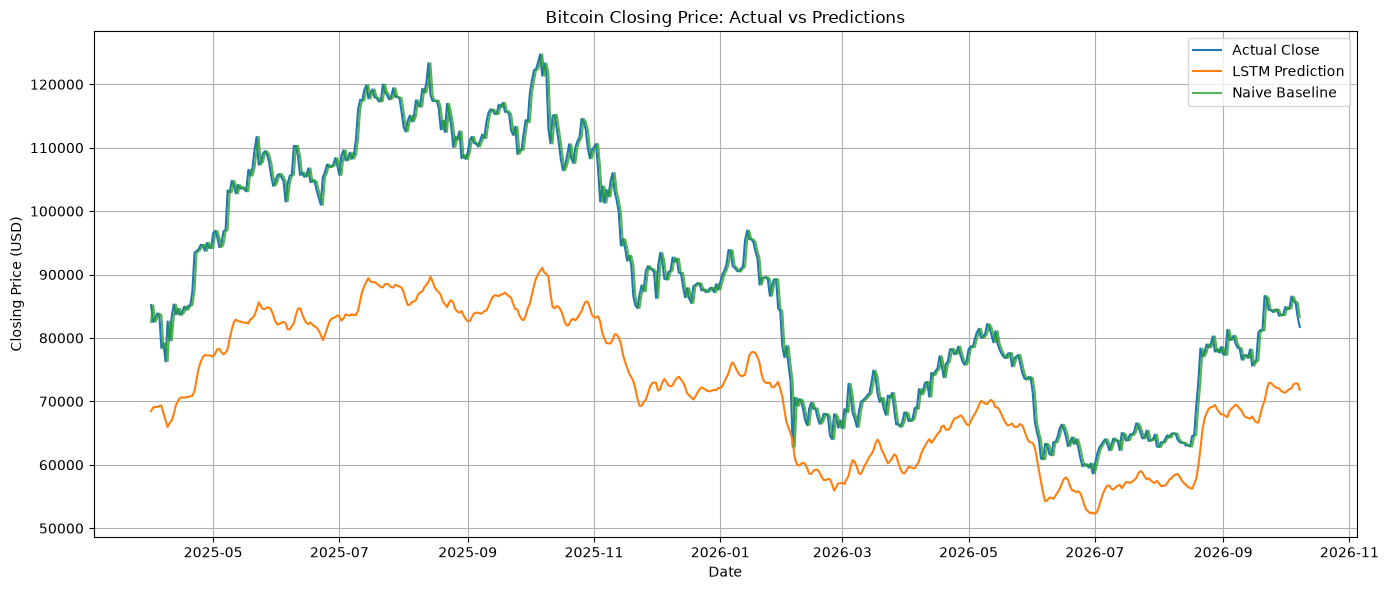

In [24]:
# Compare actual prices and predictions
plt.figure(figsize=(14, 6))

plt.plot(
    test_comparison["date"],
    y_test_actual.flatten(),
    label="Actual Close"
)

plt.plot(
    test_comparison["date"],
    y_test_pred.flatten(),
    label="LSTM Prediction"
)

plt.plot(
    test_comparison["date"],
    y_test_baseline.flatten(),
    label="Naive Baseline",
    alpha=0.8
)

plt.title("Bitcoin Closing Price: Actual vs Predictions")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
# Check scaled target ranges
print("Training target range:")
print("Min:", y_train_scaled.min())
print("Max:", y_train_scaled.max())

print("\nValidation target range:")
print("Min:", y_val_scaled.min())
print("Max:", y_val_scaled.max())

print("\nTest target range:")
print("Min:", y_test_scaled.min())
print("Max:", y_test_scaled.max())

print("\nFirst 5 actual test targets (scaled):")
print(y_test_seq[:5].flatten())

print("\nFirst 5 LSTM predictions (scaled):")
print(y_test_pred_scaled[:5].flatten())

Training target range:
Min: 0.0
Max: 1.0

Validation target range:
Min: 0.3411821697630103
Max: 1.6004907198804823

Test target range:
Min: 0.8616306368987081
Max: 1.889548933511444

First 5 actual test targets (scaled):
[1.27428523 1.23323955 1.24310627 1.25410612 1.24921407]

First 5 LSTM predictions (scaled):
[1.0145377 1.0231526 1.0251898 1.024585  1.02713  ]


In [26]:
# Find the epoch with the lowest validation loss
best_epoch = np.argmin(history.history["val_loss"]) + 1
best_val_loss = min(history.history["val_loss"])

print("Best epoch:", best_epoch)
print("Lowest validation loss:", best_val_loss)
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

Best epoch: 48
Lowest validation loss: 0.017085449770092964
Final training loss: 0.0015058029675856233
Final validation loss: 0.024802453815937042


In [27]:
# Calculate the prediction bias
prediction_bias = np.mean(y_test_pred - y_test_actual)

print(f"Mean prediction bias: ${prediction_bias:,.2f}")

if prediction_bias < 0:
    print("The model systematically underpredicts the closing price.")
elif prediction_bias > 0:
    print("The model systematically overpredicts the closing price.")
else:
    print("The model has no average prediction bias.")

Mean prediction bias: $-16,622.32
The model systematically underpredicts the closing price.


In [28]:
# Predict validation closing prices
y_val_pred_scaled = model.predict(X_val_seq)

# Convert predictions and actual values back to USD
y_val_pred = target_scaler.inverse_transform(y_val_pred_scaled)
y_val_actual = target_scaler.inverse_transform(y_val_seq)

# Calculate validation metrics
val_mae = mean_absolute_error(y_val_actual, y_val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val_actual, y_val_pred))
val_r2 = r2_score(y_val_actual, y_val_pred)

print(f"Validation MAE:  ${val_mae:,.2f}")
print(f"Validation RMSE: ${val_rmse:,.2f}")
print(f"Validation R²:   {val_r2:.4f}")

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Validation MAE:  $6,746.61
Validation RMSE: $8,404.63
Validation R²:   0.7290


In [29]:
# Compare closing price ranges across all datasets
print("Training close range:")
print(train_df["close"].min(), "to", train_df["close"].max())

print("\nValidation close range:")
print(validation_df["close"].min(), "to", validation_df["close"].max())

print("\nTest close range:")
print(test_df["close"].min(), "to", test_df["close"].max())

Training close range:
3228.681884765625 to 67527.8515625

Validation close range:
25166.412109375 to 106138.90625

Test close range:
58630.81640625 to 124725.109375


In [30]:
# Compare scaled input feature ranges
print("Training scaled feature range:")
print("Min:", X_train_scaled.min())
print("Max:", X_train_scaled.max())

print("\nValidation scaled feature range:")
print("Min:", X_val_scaled.min())
print("Max:", X_val_scaled.max())

print("\nTest scaled feature range:")
print("Min:", X_test_scaled.min())
print("Max:", X_test_scaled.max())

Training scaled feature range:
Min: 0.0
Max: 1.0

Validation scaled feature range:
Min: 2.4186024839004543e-06
Max: 1.6177482470140492

Test scaled feature range:
Min: -0.08178869444153897
Max: 1.9259773627695904


In [31]:
# Check scaled feature ranges individually
print("Training feature ranges:")
print(pd.DataFrame({
    "min": X_train_scaled.min(axis=0),
    "max": X_train_scaled.max(axis=0)
}, index=feature_columns))

print("\nTest feature ranges:")
print(pd.DataFrame({
    "min": X_test_scaled.min(axis=0),
    "max": X_test_scaled.max(axis=0)
}, index=feature_columns))

Training feature ranges:
        min  max
open    0.0  1.0
high    0.0  1.0
low     0.0  1.0
close   0.0  1.0
volume  0.0  1.0
RSI     0.0  1.0
SMA     0.0  1.0
MACD    0.0  1.0

Test feature ranges:
             min       max
open    0.861444  1.888938
high    0.866693  1.870443
low     0.865378  1.899486
close   0.861631  1.889549
volume  0.000003  0.000058
RSI     0.066463  0.950567
SMA     0.979119  1.925977
MACD   -0.081789  0.901030
